In [8]:
import numpy as np
from scipy import stats

hours_studied = [
    13.2, 8.3, 10.7, 8.9, 0.9, 4.0, 3.9, 15.8, 8.5, 11.9,
    6.4, 12.3, 7.4, 7.0, 9.5, 8.9, 37.4, 3.9, 2.0, 10.5,
    4.5, 0.7, 3.2, 32.3, 3.9, 1.4, 31.0, 3.1, 44.7, 6.2,
    25.2, 6.8, 11.5, 7.5, 6.9, 9.9, 11.8, 9.4, 8.7, 4.5,
    7.7, 23.2, 4.3, 10.1, 18.6, 11.8, 15.9, 3.0, 10.2, 6.6,
    6.8, 21.9, 6.9, 10.4, 1.4, 25.2, 15.2, 7.9, 6.4, 12.7,
    18.5, 25.4, 14.9, 8.8, 16.5, 14.5, 8.8, 14.2, 14.0, 7.9,
    5.4, 13.2, 3.4, 2.7, 10.5, 12.9, 10.5, 11.3, 12.8, 22.0,
    15.1, 14.8, 9.9, 10.2, 7.4, 11.1, 3.2, 22.0, 4.1, 15.1,
    20.2, 15.0, 34.2, 0.9, 5.7, 20.0, 2.6, 4.2, 12.2, 8.7,
]
x = np.array(hours_studied)
n = len(x)

# Sample mean
sample_mean = x.mean()

# Classical 95% CI (t-interval)
se = x.std(ddof=1) / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n - 1)
classical_ci = (sample_mean - t_crit * se, sample_mean + t_crit * se)

# Bootstrap 95% CI (percentile method, B = 10,000)
rng = np.random.default_rng(42)
B = 10_000
boot_means = rng.choice(x, size=(B, n), replace=True).mean(axis=1)
boot_ci = tuple(np.percentile(boot_means, [2.5, 97.5]))

print(f"n = {n}")
print(f"Sample mean:          {sample_mean:.2f}")
print(f"Classical 95% CI:     ({classical_ci[0]:.2f}, {classical_ci[1]:.2f})")
print(f"Bootstrap 95% CI:     ({boot_ci[0]:.2f}, {boot_ci[1]:.2f})")

n = 100
Sample mean:          11.36
Classical 95% CI:     (9.73, 12.98)
Bootstrap 95% CI:     (9.85, 13.01)


In [9]:
boot_medians = np.median(rng.choice(x, size=(B, n), replace=True), axis=1)
median_ci = tuple(np.percentile(boot_medians, [2.5, 97.5]))

print(f"Sample median:        {np.median(x):.1f}")
print(f"Bootstrap 95% CI:     ({median_ci[0]:.1f}, {median_ci[1]:.1f})")

Sample median:        9.9
Bootstrap 95% CI:     (8.5, 11.1)


Mean: estimate = 11.36, 95% CI = (9.86, 13.02)
Median: estimate = 9.90, 95% CI = (8.50, 11.10)
95th percentile: estimate = 25.68, 95% CI = (21.96, 34.36)


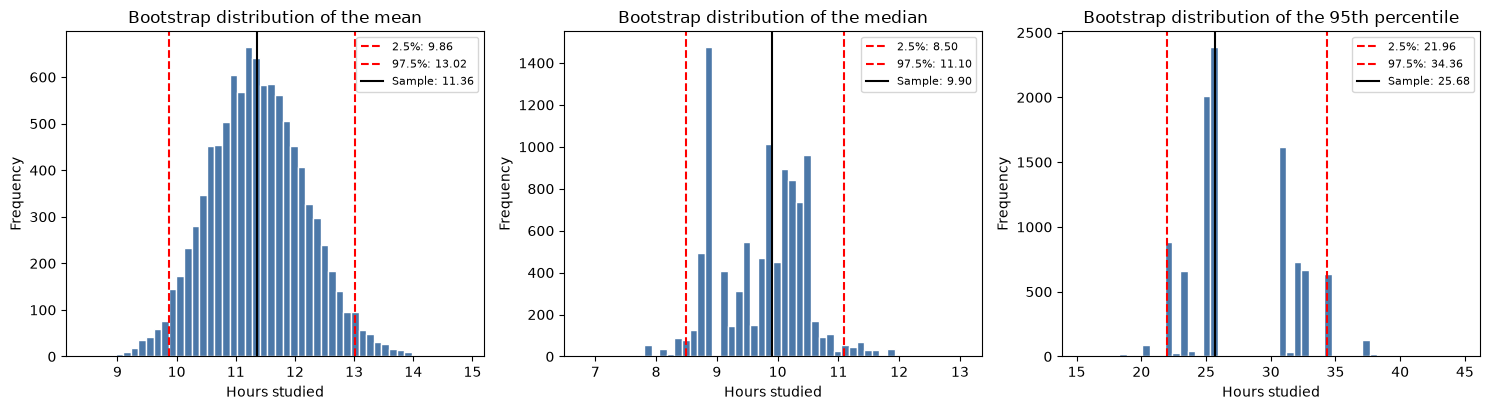

In [10]:
import matplotlib.pyplot as plt

stats_to_run = {
    "Mean": (np.mean, x.mean()),
    "Median": (np.median, np.median(x)),
    "95th percentile": (lambda a, axis: np.percentile(a, 95, axis=axis), np.percentile(x, 95)),
}

samples = x[rng.integers(0, n, size=(B, n))]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, (func, est)) in zip(axes, stats_to_run.items()):
    boot = func(samples, axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{name}: estimate = {est:.2f}, 95% CI = ({lo:.2f}, {hi:.2f})")

    ax.hist(boot, bins=50, color="#4C78A8", edgecolor="white")
    ax.axvline(lo, color="red", linestyle="--", label=f"2.5%: {lo:.2f}")
    ax.axvline(hi, color="red", linestyle="--", label=f"97.5%: {hi:.2f}")
    ax.axvline(est, color="black", label=f"Sample: {est:.2f}")
    ax.set_title(f"Bootstrap distribution of the {name.lower()}")
    ax.set_xlabel("Hours studied")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()